
# 09a — dl data audit

## Purpose

This notebook prepares and audits the data contract for the deep-learning tier of the dissertation:

**A Comparative Evaluation of Statistical, Machine Learning and Deep Learning Methods for Spatio-Temporal PM2.5 Imputation in the London AURN Monitoring Network**

It does **not** tune or fit the final deep-learning model. Its role is to lock and verify the inputs before model development.

### Locked model-family direction

The primary deep-learning approach is a compact **GRIN-inspired graph-enhanced bidirectional GRU imputation model**:

- monitoring stations are graph nodes;
- top-three inverse-distance-weighted relationships define directed neighbour messages;
- one graph/message-passing stage captures cross-station information;
- a separate self-information pathway remains active in every model variant;
- bidirectional recurrent processing captures past and future temporal context;
- the spatial ablation uses an all-zero neighbour-adjacency matrix while preserving the same self pathway, model class and parameterisation;
- neighbour projection uses `bias=False`, so zero adjacency produces an exact zero neighbour contribution;
- no BatchNorm or post-fusion LayerNorm is used;
- Train artificial masks are resampled deterministically across epochs;
- Validation selection and Test evaluation use the existing five masking scenarios.

The implementation is described as **GRIN-inspired**, not as the original GRIN architecture, because it uses a simplified graph-aggregation stage followed by a bidirectional GRU.

The architecture is deliberately compact because the graph contains only five stations.

## Experimental contract inherited from earlier notebooks

The deep-learning tier must preserve:

- Train: 2021–2023
- Validation: 2024
- Test: 2025
- no fixed artificial masks in Train
- the same five Validation/Test masking scenarios
- evaluation only at artificially masked positions
- the same Test target rows used by the statistical and machine-learning tiers
- MAE, RMSE, MedianAE and R²
- Train-only normalisation statistics
- frozen configuration before Test evaluation
- runtime metadata and prediction-reproduction audits

Expected Test target counts:

| Scenario | Expected Test targets |
|---|---:|
| random10_point | 4,318 |
| random30_point | 12,954 |
| random50_point | 21,590 |
| block24_10percent | 4,392 |
| block72_10percent | 4,536 |

In [1]:
# ============================================================
# Step 1: Imports, deterministic settings and device audit
# ============================================================

from __future__ import annotations

import hashlib
import json
import platform
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd

try:
    import torch
except ImportError as exc:
    raise ImportError(
        "PyTorch is required for Notebook 08. Install PyTorch in the "
        "dissertation environment before continuing."
    ) from exc

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
if torch.cuda.is_available():
    print("CUDA device:", torch.cuda.get_device_name(0))
print("Platform:", platform.platform())

Python: 3.11.15
NumPy: 2.4.6
pandas: 3.0.5
PyTorch: 2.11.0+cu128
Device: cuda
CUDA device: NVIDIA GeForce GTX 1660 Ti
Platform: Windows-10-10.0.19045-SP0


In [2]:
# ============================================================
# Step 2: Resolve the dissertation project structure
# ============================================================

def find_codes_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path.cwd().parent.parent,
        Path.home() / "Desktop" / "DISSERTATION" / "Codes",
        Path("/mnt/data"),
    ]

    for candidate in candidates:
        candidate = candidate.resolve()

        if (
            (candidate / "data").exists()
            and (
                (candidate / "notebooks").exists()
                or (candidate / "models").exists()
                or (candidate / "results").exists()
            )
        ):
            return candidate

        if candidate.name == "notebooks" and (candidate.parent / "data").exists():
            return candidate.parent

        if (
            (candidate / "base_modelling_dataset_before_masking.csv").exists()
            and (candidate / "top3_idw_weights.csv").exists()
        ):
            return candidate

    raise FileNotFoundError(
        "Could not locate the dissertation Codes root. Open this notebook from "
        "Codes/notebooks or update find_codes_root()."
    )


CODES_ROOT = find_codes_root()

if (CODES_ROOT / "data").exists():
    PROCESSED_DIR = CODES_ROOT / "data" / "processed"
    MODELLING_DIR = CODES_ROOT / "data" / "modelling"
    NOTEBOOKS_DIR = CODES_ROOT / "notebooks"

    RESULTS_DIR = CODES_ROOT / "results"
    DL_RESULTS_DIR = RESULTS_DIR / "deep_learning"

    OUTPUT_DIR = (
        DL_RESULTS_DIR
        / "08a_data_audit"
    )

    MODEL_DIR = (
        CODES_ROOT
        / "models"
        / "deep_learning"
    )

else:
    # Yalnız notebook full repository xaricində test edilərsə.
    PROCESSED_DIR = CODES_ROOT
    MODELLING_DIR = CODES_ROOT
    NOTEBOOKS_DIR = CODES_ROOT

    RESULTS_DIR = CODES_ROOT / "results"
    DL_RESULTS_DIR = RESULTS_DIR / "deep_learning"

    OUTPUT_DIR = (
        DL_RESULTS_DIR
        / "08a_data_audit"
    )

    MODEL_DIR = (
        CODES_ROOT
        / "models"
        / "deep_learning"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Codes root:", CODES_ROOT)
print("Processed directory:", PROCESSED_DIR)
print("Modelling directory:", MODELLING_DIR)
print("Results directory:", RESULTS_DIR)
print("DL results directory:", DL_RESULTS_DIR)
print("08a audit output directory:", OUTPUT_DIR)
print("DL model directory:", MODEL_DIR)

Codes root: C:\Users\Msi\Desktop\DISSERTATION\Codes
Processed directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\processed
Modelling directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling
Results directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results
DL results directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning
08a audit output directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit
DL model directory: C:\Users\Msi\Desktop\DISSERTATION\Codes\models\deep_learning


In [3]:
# ============================================================
# Step 3: Locked scenario, graph, training and tuning contract
# ============================================================

SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
    "block24_10percent",
    "block72_10percent",
]

RANDOM_SCENARIOS = [
    "random10_point",
    "random30_point",
    "random50_point",
]

BLOCK_SCENARIOS = [
    "block24_10percent",
    "block72_10percent",
]

EXPECTED_TEST_TARGETS = {
    "random10_point": 4318,
    "random30_point": 12954,
    "random50_point": 21590,
    "block24_10percent": 4392,
    "block72_10percent": 4536,
}

EXPECTED_SPLITS = ["Train", "Validation", "Test"]
EXPECTED_N_STATIONS = 5

CONTEXT_HOURS_CANDIDATES = [96, 168]
WINDOW_LENGTH_CANDIDATES = [
    context_hours + 1
    for context_hours in CONTEXT_HOURS_CANDIDATES
]

GRAPH_MESSAGE_LAYERS = 1
NEIGHBOUR_PROJECTION_BIAS = False
USE_BATCH_NORM = False
USE_POST_FUSION_LAYER_NORM = False
BIDIRECTIONAL_RECURRENT = True

TRAINING_LOSS = "masked_l1"
EARLY_STOPPING_METRIC = "FamilyBalancedValidationMAE"
MAX_EPOCHS = 100
EARLY_STOPPING_PATIENCE = 10
RESTORE_BEST_EPOCH = True

TRAIN_MASK_BASE_SEED = 42000
TRAIN_MASKING_SCHEDULE = "deterministic_epoch_wise_resampling"

BATCH_SIZE = 32
DATALOADER_NUM_WORKERS = 0
N_TUNING_CANDIDATES = 12

TUNED_HYPERPARAMETER_SPACE = {
    "context_hours": [96, 168],
    "hidden_units": [32, 64],
    "recurrent_layers": [1, 2],
    "dropout": [0.0, 0.2, 0.4],
    "learning_rate": [1e-3, 5e-4, 2e-4],
}

FIXED_TRAINING_SETTINGS = {
    "batch_size": BATCH_SIZE,
    "graph_message_layers": GRAPH_MESSAGE_LAYERS,
    "training_loss": TRAINING_LOSS,
    "maximum_epochs": MAX_EPOCHS,
    "early_stopping_patience": EARLY_STOPPING_PATIENCE,
    "early_stopping_metric": EARLY_STOPPING_METRIC,
    "restore_best_epoch": RESTORE_BEST_EPOCH,
    "dataloader_num_workers": DATALOADER_NUM_WORKERS,
}

print("Scenarios:", SCENARIOS)
print("Context hours:", CONTEXT_HOURS_CANDIDATES)
print("Window lengths including target step:", WINDOW_LENGTH_CANDIDATES)
print("Training loss:", TRAINING_LOSS)
print("Early-stopping metric:", EARLY_STOPPING_METRIC)
print("Tuned hyperparameters:", list(TUNED_HYPERPARAMETER_SPACE))
print("Candidate budget:", N_TUNING_CANDIDATES)
print("Fixed batch size:", BATCH_SIZE)

Scenarios: ['random10_point', 'random30_point', 'random50_point', 'block24_10percent', 'block72_10percent']
Context hours: [96, 168]
Window lengths including target step: [97, 169]
Training loss: masked_l1
Early-stopping metric: FamilyBalancedValidationMAE
Tuned hyperparameters: ['context_hours', 'hidden_units', 'recurrent_layers', 'dropout', 'learning_rate']
Candidate budget: 12
Fixed batch size: 32


In [4]:
# ============================================================
# Step 4: Locate and load base, spatial and scenario inputs
# ============================================================

def first_existing(paths: list[Path]) -> Path:
    for path in paths:
        if path.exists():
            return path
    raise FileNotFoundError(
        "None of the expected files exists:\n" + "\n".join(map(str, paths))
    )


base_path = first_existing([
    MODELLING_DIR / "base_modelling_dataset_before_masking.csv",
    PROCESSED_DIR / "base_modelling_dataset_before_masking.csv",
])

metadata_path = first_existing([
    PROCESSED_DIR / "selected_station_metadata.csv",
    MODELLING_DIR / "selected_station_metadata.csv",
])

idw_path = first_existing([
    PROCESSED_DIR / "top3_idw_weights.csv",
    MODELLING_DIR / "top3_idw_weights.csv",
])

neighbour_path = first_existing([
    PROCESSED_DIR / "top3_nearest_neighbours.csv",
    MODELLING_DIR / "top3_nearest_neighbours.csv",
])

scenario_paths = {
    scenario: first_existing([
        MODELLING_DIR / f"modelling_dataset_{scenario}_masked.csv",
        PROCESSED_DIR / f"modelling_dataset_{scenario}_masked.csv",
    ])
    for scenario in SCENARIOS
}

base_df = pd.read_csv(base_path, parse_dates=["Datetime"])
metadata_df = pd.read_csv(metadata_path)
idw_df = pd.read_csv(idw_path)
neighbour_df = pd.read_csv(neighbour_path)

scenario_dfs = {
    scenario: pd.read_csv(path, parse_dates=["Datetime"])
    for scenario, path in scenario_paths.items()
}

print("Base:", base_path, base_df.shape)
print("Metadata:", metadata_path, metadata_df.shape)
print("IDW:", idw_path, idw_df.shape)
for scenario, df in scenario_dfs.items():
    print(f"{scenario}: {scenario_paths[scenario]} {df.shape}")

Base: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling\base_modelling_dataset_before_masking.csv (219120, 20)
Metadata: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\processed\selected_station_metadata.csv (5, 7)
IDW: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\processed\top3_idw_weights.csv (15, 6)
random10_point: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling\modelling_dataset_random10_point_masked.csv (219120, 21)
random30_point: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling\modelling_dataset_random30_point_masked.csv (219120, 21)
random50_point: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling\modelling_dataset_random50_point_masked.csv (219120, 21)
block24_10percent: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling\modelling_dataset_block24_10percent_masked.csv (219120, 21)
block72_10percent: C:\Users\Msi\Desktop\DISSERTATION\Codes\data\modelling\modelling_dataset_block72_10percent_masked.csv (219120, 21)


In [5]:
# ============================================================
# Step 5: Core panel and masking audits
# ============================================================

REQUIRED_COLUMNS = {
    "Station",
    "Datetime",
    "Split",
    "Temperature",
    "PM25_original",
    "PM25_model_input",
    "is_real_missing",
    "is_artificial_masked",
}

def audit_panel(df: pd.DataFrame, name: str) -> None:
    missing_columns = REQUIRED_COLUMNS.difference(df.columns)
    assert not missing_columns, f"{name}: missing columns {sorted(missing_columns)}"

    duplicate_count = int(df.duplicated(["Station", "Datetime"]).sum())
    assert duplicate_count == 0, f"{name}: {duplicate_count} Station-Datetime duplicates"

    assert set(df["Split"].dropna().unique()) == set(EXPECTED_SPLITS), (
        f"{name}: unexpected split labels {sorted(df['Split'].dropna().unique())}"
    )

    assert df["Station"].nunique() == EXPECTED_N_STATIONS, (
        f"{name}: expected {EXPECTED_N_STATIONS} stations, "
        f"found {df['Station'].nunique()}"
    )

    train_artificial = int(
        df.loc[df["Split"].eq("Train"), "is_artificial_masked"].sum()
    )
    assert train_artificial == 0, (
        f"{name}: Train has {train_artificial} artificial masks"
    )

    masked_rows = df["is_artificial_masked"].astype(bool)

    assert df.loc[masked_rows, "PM25_original"].notna().all(), (
        f"{name}: artificial targets without known PM25_original"
    )
    assert df.loc[masked_rows, "PM25_model_input"].isna().all(), (
        f"{name}: artificial targets remain visible in PM25_model_input"
    )
    assert not df.loc[masked_rows, "is_real_missing"].astype(bool).any(), (
        f"{name}: real missing rows were used as artificial targets"
    )

    print(f"{name}: core audit passed.")


audit_panel(base_df, "base")
for scenario, df in scenario_dfs.items():
    audit_panel(df, scenario)

base_keys = (
    base_df[["Station", "Datetime", "Split"]]
    .sort_values(["Station", "Datetime"])
    .reset_index(drop=True)
)

for scenario, df in scenario_dfs.items():
    scenario_keys = (
        df[["Station", "Datetime", "Split"]]
        .sort_values(["Station", "Datetime"])
        .reset_index(drop=True)
    )
    pd.testing.assert_frame_equal(base_keys, scenario_keys)

print("All scenario panels match the base Station-Datetime-Split keys.")

base: core audit passed.
random10_point: core audit passed.
random30_point: core audit passed.
random50_point: core audit passed.
block24_10percent: core audit passed.
block72_10percent: core audit passed.
All scenario panels match the base Station-Datetime-Split keys.


In [6]:
# ============================================================
# Step 6: Exact Validation/Test target audits
# ============================================================

target_summary_records = []

for scenario, df in scenario_dfs.items():
    for split_name in ["Validation", "Test"]:
        target_rows = df.loc[
            df["Split"].eq(split_name)
            & df["is_artificial_masked"].astype(bool)
        ]

        target_summary_records.append({
            "Scenario": scenario,
            "Split": split_name,
            "TargetRows": int(len(target_rows)),
            "UniqueTargetTimestamps": int(target_rows["Datetime"].nunique()),
            "StationsWithTargets": int(target_rows["Station"].nunique()),
        })

        if split_name == "Test":
            expected = EXPECTED_TEST_TARGETS[scenario]
            assert len(target_rows) == expected, (
                f"{scenario}: expected {expected} Test targets, "
                f"found {len(target_rows)}"
            )

target_summary_df = pd.DataFrame(target_summary_records)
display(target_summary_df)

target_summary_path = OUTPUT_DIR / "dl_target_count_audit.csv"
target_summary_df.to_csv(target_summary_path, index=False)

print("Exact Test target counts passed.")
print("Saved:", target_summary_path)

,Scenario,Split,TargetRows,UniqueTargetTimestamps,StationsWithTargets
0,random10_point,Validation,4332,3594,5
1,random10_point,Test,4318,3536,5
2,random30_point,Validation,12997,7284,5
3,random30_point,Test,12954,7259,5
4,random50_point,Validation,21660,8489,5
5,random50_point,Test,21590,8455,5
6,block24_10percent,Validation,4392,3662,5
7,block24_10percent,Test,4392,3546,5
8,block72_10percent,Validation,4608,3547,5
9,block72_10percent,Test,4536,3854,5


Exact Test target counts passed.
Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_target_count_audit.csv


In [7]:
# ============================================================
# Step 7: Lock station order and validate spatial metadata
# ============================================================

station_order = metadata_df["Station"].astype(str).tolist()

assert len(station_order) == EXPECTED_N_STATIONS
assert len(set(station_order)) == EXPECTED_N_STATIONS
assert set(station_order) == set(base_df["Station"].astype(str).unique())

station_to_index = {
    station: index
    for index, station in enumerate(station_order)
}

expected_pairs = {
    (target, rank)
    for target in station_order
    for rank in [1, 2, 3]
}

actual_pairs = set(
    zip(
        idw_df["Target_station"].astype(str),
        idw_df["Neighbour_rank"].astype(int),
    )
)

assert actual_pairs == expected_pairs, (
    "IDW table must contain exactly three ranked neighbours for every station."
)

assert not (
    idw_df["Target_station"].astype(str)
    == idw_df["Neighbour_station"].astype(str)
).any(), "IDW table contains a self-neighbour."

weight_sums = (
    idw_df
    .groupby("Target_station", as_index=True)["IDW_weight"]
    .sum()
    .reindex(station_order)
)

np.testing.assert_allclose(
    weight_sums.to_numpy(dtype=float),
    np.ones(EXPECTED_N_STATIONS),
    atol=2e-3,
)

display(metadata_df)
display(idw_df.sort_values(["Target_station", "Neighbour_rank"]))

print("Station order:", station_order)
print("Spatial metadata audit passed.")

,Station,Latitude,Longitude,SiteType,Zone,Agglomeration,LocalAuthority
0,London Bexley,51.466030,0.184806,Suburban Background,Greater London,Greater London Urban Area,Bexley
1,London Harlington,51.488790,-0.441614,Urban Industrial,Greater London,Greater London Urban Area,Hillingdon
2,London Honor Oak Park,51.449674,-0.037418,Urban Background,Greater London,Greater London Urban Area,Lewisham
3,London Marylebone Road,51.522530,-0.154611,Urban Traffic,Greater London,Greater London Urban Area,Westminster
4,London N. Kensington,51.521050,-0.213419,Urban Background,Greater London,Greater London Urban Area,Kensington


,Target_station,Neighbour_rank,Neighbour_station,Distance_km,Inverse_distance,IDW_weight
0,London Bexley,1,London Honor Oak Park,15.50,0.064516,0.457
1,London Bexley,2,London Marylebone Road,24.32,0.041118,0.292
2,London Bexley,3,London N. Kensington,28.24,0.035411,0.251
3,London Harlington,1,London N. Kensington,16.20,0.061728,0.421
4,London Harlington,2,London Marylebone Road,20.22,0.049456,0.338
5,London Harlington,3,London Honor Oak Park,28.33,0.035298,0.241
6,London Honor Oak Park,1,London Marylebone Road,11.47,0.087184,0.395
7,London Honor Oak Park,2,London N. Kensington,14.54,0.068776,0.312
8,London Honor Oak Park,3,London Bexley,15.50,0.064516,0.293
9,London Marylebone Road,1,London N. Kensington,4.07,0.245700,0.643


Station order: ['London Bexley', 'London Harlington', 'London Honor Oak Park', 'London Marylebone Road', 'London N. Kensington']
Spatial metadata audit passed.


In [8]:
# ============================================================
# Step 8: Build the fixed top-three IDW neighbour matrix
# ============================================================

# The matrix contains cross-station neighbour messages only.
# Its diagonal is zero because the future model has a separate self pathway.
A_NEIGHBOUR = np.zeros(
    (EXPECTED_N_STATIONS, EXPECTED_N_STATIONS),
    dtype=np.float32,
)

for row in idw_df.itertuples(index=False):
    target_index = station_to_index[str(row.Target_station)]
    neighbour_index = station_to_index[str(row.Neighbour_station)]
    A_NEIGHBOUR[target_index, neighbour_index] = float(row.IDW_weight)

np.testing.assert_allclose(
    A_NEIGHBOUR.sum(axis=1),
    np.ones(EXPECTED_N_STATIONS),
    atol=2e-3,
)
np.testing.assert_allclose(
    np.diag(A_NEIGHBOUR),
    np.zeros(EXPECTED_N_STATIONS),
    atol=0.0,
)

# No-neighbour control: only cross-station messages are removed.
A_NO_NEIGHBOUR = np.zeros_like(A_NEIGHBOUR)

adjacency_df = pd.DataFrame(
    A_NEIGHBOUR,
    index=station_order,
    columns=station_order,
)

display(adjacency_df)

adjacency_path = OUTPUT_DIR / "dl_top3_idw_neighbour_adjacency.csv"
adjacency_df.to_csv(adjacency_path)

np.save(OUTPUT_DIR / "dl_top3_idw_neighbour_adjacency.npy", A_NEIGHBOUR)
np.save(OUTPUT_DIR / "dl_no_neighbour_adjacency.npy", A_NO_NEIGHBOUR)

print("Saved graph matrices.")

,London Bexley,London Harlington,London Honor Oak Park,London Marylebone Road,London N. Kensington
London Bexley,0.000,0.000,0.457,0.292,0.251
London Harlington,0.000,0.000,0.241,0.338,0.421
London Honor Oak Park,0.293,0.000,0.000,0.395,0.312
London Marylebone Road,0.000,0.129,0.228,0.000,0.643
London N. Kensington,0.000,0.164,0.183,0.653,0.000


Saved graph matrices.


## Fixed station graph visualisation

The following figures document the spatial structure supplied to the graph-recurrent model.

- The network diagram places the five AURN stations at their observed longitude and latitude.
- Arrows follow the direction of information flow: **neighbour station → target station**.
- Arrow width is proportional to the row-normalised inverse-distance weight.
- The graph is fixed before model training and contains no self-loops.
- The adjacency heatmap is retained as a technical audit and Appendix-ready artefact.

**Suggested dissertation caption**

*Fixed top-three inverse-distance station graph used by the graph-recurrent model. Nodes represent the five selected AURN monitoring stations. Directed arrows show neighbour-to-target information flow, with arrow width proportional to the row-normalised inverse-distance weight. The graph was fixed before model training and was not learned from Validation or Test data.*

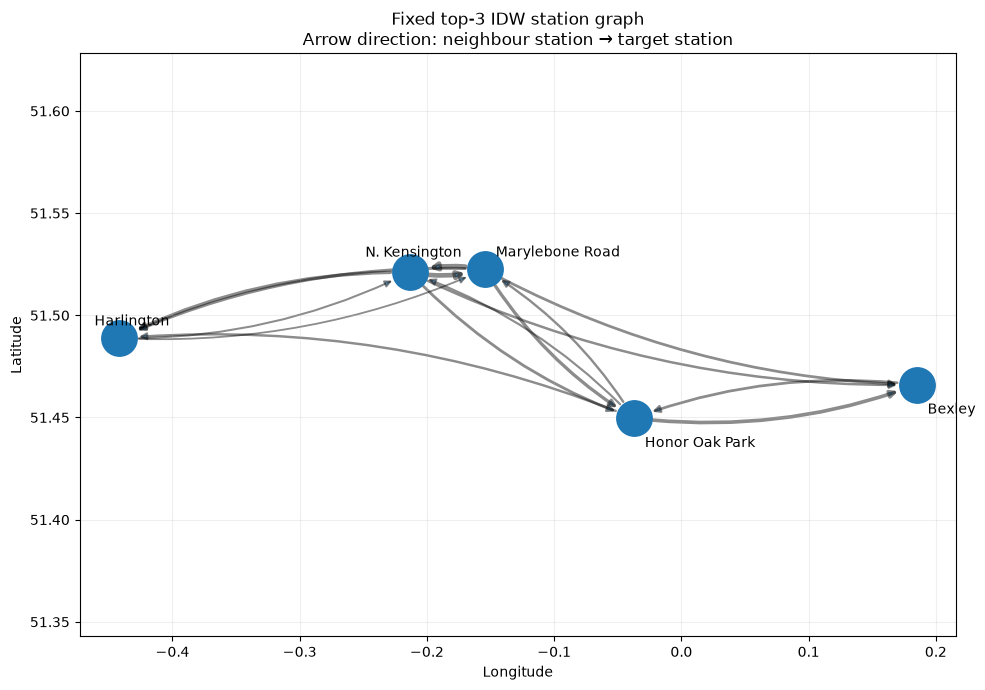

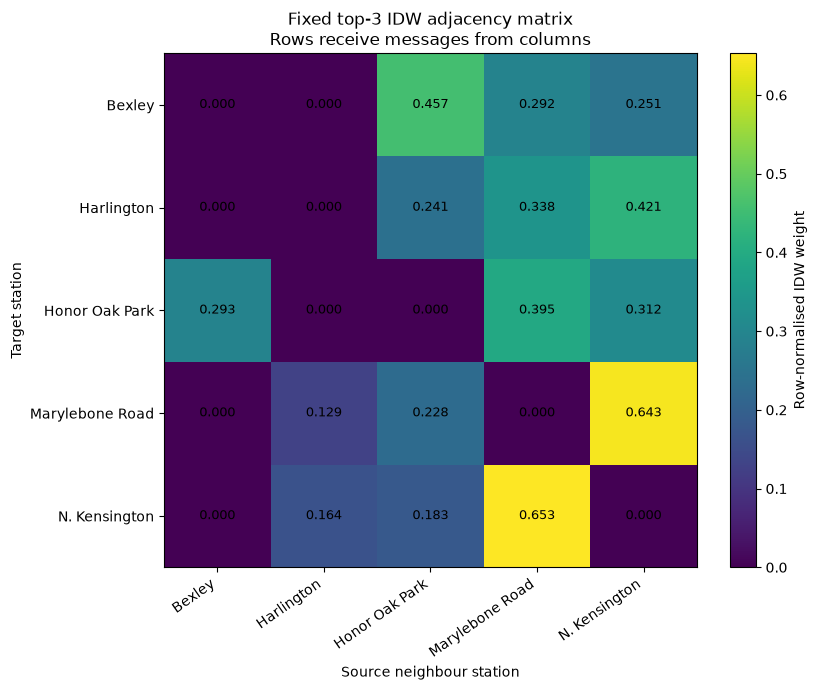

Station graph: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_top3_idw_station_graph.png
Adjacency heatmap: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_top3_idw_adjacency_heatmap.png
Directed edge list: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_top3_idw_directed_edge_list.csv


In [9]:
# ============================================================
# Step 8b: Visualise the fixed station graph and adjacency matrix
# ============================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch

short_station_labels = {
    "London Bexley": "Bexley",
    "London Harlington": "Harlington",
    "London Honor Oak Park": "Honor Oak Park",
    "London Marylebone Road": "Marylebone Road",
    "London N. Kensington": "N. Kensington",
}

station_positions = {
    str(row.Station): (
        float(row.Longitude),
        float(row.Latitude),
    )
    for row in metadata_df.itertuples(index=False)
}

assert set(station_positions) == set(station_order)

graph_edge_df = (
    idw_df[
        [
            "Target_station",
            "Neighbour_station",
            "Neighbour_rank",
            "Distance_km",
            "IDW_weight",
        ]
    ]
    .rename(
        columns={
            "Neighbour_station": "SourceNeighbourStation",
            "Target_station": "TargetStation",
            "Neighbour_rank": "NeighbourRank",
            "Distance_km": "DistanceKm",
            "IDW_weight": "IDWWeight",
        }
    )
    .sort_values(["TargetStation", "NeighbourRank"])
    .reset_index(drop=True)
)

assert len(graph_edge_df) == EXPECTED_N_STATIONS * 3
assert not (
    graph_edge_df["SourceNeighbourStation"]
    == graph_edge_df["TargetStation"]
).any()

graph_edge_list_path = (
    OUTPUT_DIR / "dl_top3_idw_directed_edge_list.csv"
)
graph_edge_df.to_csv(graph_edge_list_path, index=False)

# ------------------------------------------------------------
# Geographic network diagram
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 7))

for edge in graph_edge_df.itertuples(index=False):
    source_station = str(edge.SourceNeighbourStation)
    target_station = str(edge.TargetStation)
    weight = float(edge.IDWWeight)

    source_position = station_positions[source_station]
    target_position = station_positions[target_station]

    arrow = FancyArrowPatch(
        source_position,
        target_position,
        arrowstyle="-|>",
        mutation_scale=10,
        linewidth=0.8 + 4.0 * weight,
        alpha=0.45,
        connectionstyle="arc3,rad=0.12",
        shrinkA=14,
        shrinkB=14,
    )
    ax.add_patch(arrow)

longitudes = [
    station_positions[station][0]
    for station in station_order
]
latitudes = [
    station_positions[station][1]
    for station in station_order
]

ax.scatter(
    longitudes,
    latitudes,
    s=650,
    zorder=3,
)

label_offsets = {
    "London Bexley": (8, -18),
    "London Harlington": (-18, 12),
    "London Honor Oak Park": (8, -18),
    "London Marylebone Road": (8, 12),
    "London N. Kensington": (-32, 14),
}

for station in station_order:
    x_position, y_position = station_positions[station]
    x_offset, y_offset = label_offsets.get(station, (8, 8))

    ax.annotate(
        short_station_labels.get(station, station),
        xy=(x_position, y_position),
        xytext=(x_offset, y_offset),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=10,
        zorder=4,
    )

mean_latitude = float(np.mean(latitudes))
ax.set_aspect(
    1.0 / np.cos(np.deg2rad(mean_latitude)),
    adjustable="datalim",
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title(
    "Fixed top-3 IDW station graph\n"
    "Arrow direction: neighbour station → target station"
)
ax.grid(alpha=0.20)
fig.tight_layout()

station_graph_path = (
    OUTPUT_DIR / "dl_top3_idw_station_graph.png"
)
fig.savefig(
    station_graph_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

# ------------------------------------------------------------
# Adjacency heatmap
# Rows are target stations; columns are source neighbours.
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8.5, 7))

heatmap_image = ax.imshow(
    A_NEIGHBOUR,
    aspect="auto",
)

colorbar = fig.colorbar(
    heatmap_image,
    ax=ax,
)
colorbar.set_label("Row-normalised IDW weight")

short_labels_in_order = [
    short_station_labels.get(station, station)
    for station in station_order
]

ax.set_xticks(
    np.arange(EXPECTED_N_STATIONS),
    labels=short_labels_in_order,
    rotation=35,
    ha="right",
)
ax.set_yticks(
    np.arange(EXPECTED_N_STATIONS),
    labels=short_labels_in_order,
)

for target_index in range(EXPECTED_N_STATIONS):
    for neighbour_index in range(EXPECTED_N_STATIONS):
        ax.text(
            neighbour_index,
            target_index,
            f"{A_NEIGHBOUR[target_index, neighbour_index]:.3f}",
            ha="center",
            va="center",
            fontsize=9,
        )

ax.set_xlabel("Source neighbour station")
ax.set_ylabel("Target station")
ax.set_title(
    "Fixed top-3 IDW adjacency matrix\n"
    "Rows receive messages from columns"
)
fig.tight_layout()

adjacency_heatmap_path = (
    OUTPUT_DIR / "dl_top3_idw_adjacency_heatmap.png"
)
fig.savefig(
    adjacency_heatmap_path,
    dpi=300,
    bbox_inches="tight",
)
plt.show()

assert station_graph_path.exists()
assert adjacency_heatmap_path.exists()
assert graph_edge_list_path.exists()

print("Station graph:", station_graph_path)
print("Adjacency heatmap:", adjacency_heatmap_path)
print("Directed edge list:", graph_edge_list_path)

In [10]:
# ============================================================
# Step 9: Fit Train-only normalisation statistics
# ============================================================

train_base = base_df.loc[base_df["Split"].eq("Train")].copy()

pm25_train = pd.to_numeric(
    train_base["PM25_model_input"],
    errors="coerce",
).dropna()

temperature_train = pd.to_numeric(
    train_base["Temperature"],
    errors="coerce",
).dropna()

assert len(pm25_train) > 0
assert len(temperature_train) > 0

normalisation_stats = {
    "PM25": {
        "mean": float(pm25_train.mean()),
        "std": float(pm25_train.std(ddof=0)),
        "observed_n": int(pm25_train.shape[0]),
    },
    "Temperature": {
        "mean": float(temperature_train.mean()),
        "std": float(temperature_train.std(ddof=0)),
        "observed_n": int(temperature_train.shape[0]),
    },
}

assert normalisation_stats["PM25"]["std"] > 0
assert normalisation_stats["Temperature"]["std"] > 0

normalisation_path = OUTPUT_DIR / "dl_train_normalisation_stats.json"
normalisation_path.write_text(
    json.dumps(normalisation_stats, indent=2),
    encoding="utf-8",
)

print(json.dumps(normalisation_stats, indent=2))
print("Saved:", normalisation_path)

{
  "PM25": {
    "mean": 8.762305030114813,
    "std": 7.403844648403524,
    "observed_n": 127512
  },
  "Temperature": {
    "mean": 10.353392302917444,
    "std": 6.152809318890623,
    "observed_n": 128880
  }
}
Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_train_normalisation_stats.json


In [11]:
# ============================================================
# Step 10: Feature helpers
# ============================================================

def standardise_with_mask(
    values: np.ndarray,
    mean: float,
    std: float,
) -> tuple[np.ndarray, np.ndarray]:
    values = np.asarray(values, dtype=np.float32)
    observed = np.isfinite(values).astype(np.float32)

    standardised = (values - mean) / std
    standardised[~np.isfinite(standardised)] = 0.0

    return standardised.astype(np.float32), observed


def directional_gap_hours(
    observed_mask: np.ndarray,
    direction: str,
    max_hours: int = 168,
) -> np.ndarray:
    observed_mask = np.asarray(observed_mask, dtype=bool)
    n = len(observed_mask)
    gaps = np.full(n, max_hours, dtype=np.float32)

    if direction == "previous":
        last_observed = None
        for index in range(n):
            if observed_mask[index]:
                gaps[index] = 0.0
                last_observed = index
            elif last_observed is not None:
                gaps[index] = min(index - last_observed, max_hours)

    elif direction == "next":
        next_observed = None
        for index in range(n - 1, -1, -1):
            if observed_mask[index]:
                gaps[index] = 0.0
                next_observed = index
            elif next_observed is not None:
                gaps[index] = min(next_observed - index, max_hours)

    else:
        raise ValueError("direction must be 'previous' or 'next'")

    return (
        np.log1p(gaps)
        / np.log1p(float(max_hours))
    ).astype(np.float32)


def dataframe_sha256(df: pd.DataFrame, columns: list[str]) -> str:
    stable = (
        df[columns]
        .sort_values(columns[:2])
        .reset_index(drop=True)
    )
    payload = pd.util.hash_pandas_object(
        stable,
        index=False,
    ).to_numpy().tobytes()
    return hashlib.sha256(payload).hexdigest()

In [12]:
# ============================================================
# Step 11: Convert one scenario split into [time, station, feature]
# ============================================================

def build_split_tensor(
    scenario_df: pd.DataFrame,
    split_name: str,
    station_order: list[str],
    normalisation_stats: dict,
) -> dict:
    split_df = scenario_df.loc[
        scenario_df["Split"].eq(split_name)
    ].copy()

    split_df["Station"] = pd.Categorical(
        split_df["Station"],
        categories=station_order,
        ordered=True,
    )

    split_df = split_df.sort_values(
        ["Datetime", "Station"]
    ).reset_index(drop=True)

    timestamps = np.sort(split_df["Datetime"].unique())
    expected_rows = len(timestamps) * len(station_order)
    assert len(split_df) == expected_rows

    station_counts = split_df.groupby(
        "Datetime",
        observed=False,
    )["Station"].nunique()

    assert (station_counts == len(station_order)).all(), (
        f"{split_name}: every timestamp must contain all stations."
    )

    def pivot(column: str) -> np.ndarray:
        table = (
            split_df
            .pivot(index="Datetime", columns="Station", values=column)
            .reindex(index=timestamps, columns=station_order)
        )
        return table.to_numpy()

    pm25_input = pivot("PM25_model_input").astype(np.float32)
    pm25_truth = pivot("PM25_original").astype(np.float32)
    temperature = pivot("Temperature").astype(np.float32)

    artificial_target = pivot("is_artificial_masked").astype(bool)
    real_missing = pivot("is_real_missing").astype(bool)

    pm25_z, pm25_observed = standardise_with_mask(
        pm25_input,
        normalisation_stats["PM25"]["mean"],
        normalisation_stats["PM25"]["std"],
    )
    temperature_z, temperature_observed = standardise_with_mask(
        temperature,
        normalisation_stats["Temperature"]["mean"],
        normalisation_stats["Temperature"]["std"],
    )

    datetime_index = pd.DatetimeIndex(timestamps)

    hour_angle = 2.0 * np.pi * datetime_index.hour.to_numpy() / 24.0
    dow_angle = 2.0 * np.pi * datetime_index.dayofweek.to_numpy() / 7.0
    month_angle = 2.0 * np.pi * (datetime_index.month.to_numpy() - 1) / 12.0

    calendar = np.column_stack([
        np.sin(hour_angle),
        np.cos(hour_angle),
        np.sin(dow_angle),
        np.cos(dow_angle),
        np.sin(month_angle),
        np.cos(month_angle),
    ]).astype(np.float32)

    calendar = np.repeat(
        calendar[:, None, :],
        repeats=len(station_order),
        axis=1,
    )

    delta_previous = np.zeros_like(pm25_z, dtype=np.float32)
    delta_next = np.zeros_like(pm25_z, dtype=np.float32)

    for station_index in range(len(station_order)):
        station_observed = pm25_observed[:, station_index].astype(bool)
        delta_previous[:, station_index] = directional_gap_hours(
            station_observed,
            direction="previous",
        )
        delta_next[:, station_index] = directional_gap_hours(
            station_observed,
            direction="next",
        )

    station_one_hot = np.eye(
        len(station_order),
        dtype=np.float32,
    )
    station_one_hot = np.repeat(
        station_one_hot[None, :, :],
        repeats=len(timestamps),
        axis=0,
    )

    valid_time_mask = np.ones(
        (len(timestamps), len(station_order), 1),
        dtype=np.float32,
    )

    features = np.concatenate([
        pm25_z[..., None],
        pm25_observed[..., None],
        temperature_z[..., None],
        temperature_observed[..., None],
        calendar,
        delta_previous[..., None],
        delta_next[..., None],
        station_one_hot,
        valid_time_mask,
    ], axis=-1).astype(np.float32)

    feature_names = [
        "PM25_value_z",
        "PM25_observed_mask",
        "Temperature_z",
        "Temperature_observed_mask",
        "Hour_sin",
        "Hour_cos",
        "DayOfWeek_sin",
        "DayOfWeek_cos",
        "Month_sin",
        "Month_cos",
        "HoursSincePreviousObserved_scaled",
        "HoursUntilNextObserved_scaled",
        *[f"Station_{station}" for station in station_order],
        "ValidTimeStep",
    ]

    assert features.shape == (
        len(timestamps),
        len(station_order),
        len(feature_names),
    )

    return {
        "features": features,
        "feature_names": feature_names,
        "truth": pm25_truth,
        "artificial_target_mask": artificial_target,
        "real_missing_mask": real_missing,
        "timestamps": datetime_index,
        "station_order": station_order,
    }

In [13]:
# ============================================================
# Step 12: Tensor shape and leakage-oriented input audits
# ============================================================

tensor_audit_records = []

for scenario, df in scenario_dfs.items():
    for split_name in EXPECTED_SPLITS:
        bundle = build_split_tensor(
            scenario_df=df,
            split_name=split_name,
            station_order=station_order,
            normalisation_stats=normalisation_stats,
        )

        target_mask = bundle["artificial_target_mask"]
        features = bundle["features"]
        pm25_value_index = bundle["feature_names"].index("PM25_value_z")
        pm25_mask_index = bundle["feature_names"].index("PM25_observed_mask")

        if target_mask.any():
            assert np.allclose(
                features[..., pm25_value_index][target_mask],
                0.0,
            )
            assert np.allclose(
                features[..., pm25_mask_index][target_mask],
                0.0,
            )

        tensor_audit_records.append({
            "Scenario": scenario,
            "Split": split_name,
            "TimeSteps": int(features.shape[0]),
            "Stations": int(features.shape[1]),
            "Features": int(features.shape[2]),
            "ArtificialTargets": int(target_mask.sum()),
            "RealMissingTargets": int(bundle["real_missing_mask"].sum()),
        })

tensor_audit_df = pd.DataFrame(tensor_audit_records)
display(tensor_audit_df)

tensor_audit_path = OUTPUT_DIR / "dl_tensor_shape_audit.csv"
tensor_audit_df.to_csv(tensor_audit_path, index=False)

print("Tensor and target-hiding audits passed.")
print("Saved:", tensor_audit_path)

,Scenario,Split,TimeSteps,Stations,Features,ArtificialTargets,RealMissingTargets
0,random10_point,Train,26280,5,18,0,3888
1,random10_point,Validation,8784,5,18,4332,600
2,random10_point,Test,8760,5,18,4318,619
3,random30_point,Train,26280,5,18,0,3888
4,random30_point,Validation,8784,5,18,12997,600
5,random30_point,Test,8760,5,18,12954,619
6,random50_point,Train,26280,5,18,0,3888
7,random50_point,Validation,8784,5,18,21660,600
8,random50_point,Test,8760,5,18,21590,619
9,block24_10percent,Train,26280,5,18,0,3888


Tensor and target-hiding audits passed.
Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_tensor_shape_audit.csv


In [14]:
# ============================================================
# Step 13: Centred window extraction with explicit padding
# ============================================================

def extract_centred_window(
    features: np.ndarray,
    center_index: int,
    context_hours: int,
) -> np.ndarray:
    """
    Extract half the context before and half after the target timestamp,
    plus the current target step.

    For 96 context hours, output length is 97.
    For 168 context hours, output length is 169.
    """
    if context_hours % 2 != 0:
        raise ValueError("context_hours must be even")

    radius = context_hours // 2
    window_length = context_hours + 1

    start = center_index - radius
    end = center_index + radius + 1

    window = np.zeros(
        (window_length, features.shape[1], features.shape[2]),
        dtype=np.float32,
    )

    source_start = max(start, 0)
    source_end = min(end, features.shape[0])

    destination_start = source_start - start
    destination_end = destination_start + (source_end - source_start)

    window[destination_start:destination_end] = features[source_start:source_end]

    return window


synthetic = np.ones((10, 5, 3), dtype=np.float32)

first_window = extract_centred_window(
    synthetic,
    center_index=0,
    context_hours=4,
)
middle_window = extract_centred_window(
    synthetic,
    center_index=5,
    context_hours=4,
)
last_window = extract_centred_window(
    synthetic,
    center_index=9,
    context_hours=4,
)

assert first_window.shape == (5, 5, 3)
assert middle_window.shape == (5, 5, 3)
assert last_window.shape == (5, 5, 3)

assert np.allclose(first_window[:2], 0.0)
assert np.allclose(middle_window, 1.0)
assert np.allclose(last_window[-2:], 0.0)

print("Centred-window padding tests passed.")

Centred-window padding tests passed.


In [15]:
# ============================================================
# Step 14: Audit window coverage for Validation/Test targets
# ============================================================

window_audit_records = []

for scenario, df in scenario_dfs.items():
    for split_name in ["Validation", "Test"]:
        bundle = build_split_tensor(
            scenario_df=df,
            split_name=split_name,
            station_order=station_order,
            normalisation_stats=normalisation_stats,
        )

        target_mask = bundle["artificial_target_mask"]
        target_time_indices = np.flatnonzero(target_mask.any(axis=1))

        for context_hours in CONTEXT_HOURS_CANDIDATES:
            for time_index in target_time_indices[: min(25, len(target_time_indices))]:
                window = extract_centred_window(
                    bundle["features"],
                    center_index=int(time_index),
                    context_hours=context_hours,
                )
                assert window.shape[0] == context_hours + 1

            window_audit_records.append({
                "Scenario": scenario,
                "Split": split_name,
                "ContextHours": context_hours,
                "WindowLength": context_hours + 1,
                "TargetRows": int(target_mask.sum()),
                "UniqueTargetTimestamps": int(len(target_time_indices)),
            })

window_audit_df = pd.DataFrame(window_audit_records)
display(window_audit_df)

window_audit_path = OUTPUT_DIR / "dl_window_coverage_audit.csv"
window_audit_df.to_csv(window_audit_path, index=False)

print("All target timestamps can be represented by centred padded windows.")
print("Saved:", window_audit_path)

,Scenario,Split,ContextHours,WindowLength,TargetRows,UniqueTargetTimestamps
0,random10_point,Validation,96,97,4332,3594
1,random10_point,Validation,168,169,4332,3594
2,random10_point,Test,96,97,4318,3536
3,random10_point,Test,168,169,4318,3536
4,random30_point,Validation,96,97,12997,7284
5,random30_point,Validation,168,169,12997,7284
6,random30_point,Test,96,97,12954,7259
7,random30_point,Test,168,169,12954,7259
8,random50_point,Validation,96,97,21660,8489
9,random50_point,Validation,168,169,21660,8489


All target timestamps can be represented by centred padded windows.
Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_window_coverage_audit.csv


In [16]:
# ============================================================
# Step 14b: Lock one-window-per-target-timestamp evaluation
# ============================================================

def build_unique_target_timestamp_index(bundle: dict) -> pd.DataFrame:
    target_mask = bundle["artificial_target_mask"]
    timestamps = bundle["timestamps"]
    station_order_local = bundle["station_order"]

    records = []

    for time_index in np.flatnonzero(target_mask.any(axis=1)):
        masked_station_indices = np.flatnonzero(target_mask[time_index])

        records.append({
            "TimeIndex": int(time_index),
            "Datetime": pd.Timestamp(timestamps[time_index]),
            "MaskedStationIndices": masked_station_indices.tolist(),
            "MaskedStations": [
                station_order_local[index]
                for index in masked_station_indices
            ],
            "NTargetsAtTimestamp": int(len(masked_station_indices)),
        })

    return pd.DataFrame(records)


target_alignment_records = []

for scenario, df in scenario_dfs.items():
    for split_name in ["Validation", "Test"]:
        bundle = build_split_tensor(
            scenario_df=df,
            split_name=split_name,
            station_order=station_order,
            normalisation_stats=normalisation_stats,
        )

        target_index_df = build_unique_target_timestamp_index(bundle)

        assert not target_index_df["Datetime"].duplicated().any()

        extracted_target_count = int(
            target_index_df["NTargetsAtTimestamp"].sum()
        )
        expected_target_count = int(
            bundle["artificial_target_mask"].sum()
        )

        assert extracted_target_count == expected_target_count

        if split_name == "Test":
            assert extracted_target_count == EXPECTED_TEST_TARGETS[scenario]

        target_alignment_records.append({
            "Scenario": scenario,
            "Split": split_name,
            "UniqueCentredWindows": int(len(target_index_df)),
            "ExtractedTargetRows": extracted_target_count,
            "ExpectedTargetRows": expected_target_count,
            "DuplicateTargetPredictions": 0,
            "ExtractionRule": (
                "one centred window per unique target timestamp; "
                "centre-step predictions retained only for masked nodes"
            ),
        })

target_alignment_audit_df = pd.DataFrame(target_alignment_records)
display(target_alignment_audit_df)

target_alignment_path = OUTPUT_DIR / "dl_target_alignment_audit.csv"
target_alignment_audit_df.to_csv(target_alignment_path, index=False)

print("Target-alignment audit passed.")
print("Saved:", target_alignment_path)

,Scenario,Split,UniqueCentredWindows,ExtractedTargetRows,ExpectedTargetRows,DuplicateTargetPredictions,ExtractionRule
0,random10_point,Validation,3594,4332,4332,0,one centred window per unique target timestamp...
1,random10_point,Test,3536,4318,4318,0,one centred window per unique target timestamp...
2,random30_point,Validation,7284,12997,12997,0,one centred window per unique target timestamp...
3,random30_point,Test,7259,12954,12954,0,one centred window per unique target timestamp...
4,random50_point,Validation,8489,21660,21660,0,one centred window per unique target timestamp...
5,random50_point,Test,8455,21590,21590,0,one centred window per unique target timestamp...
6,block24_10percent,Validation,3662,4392,4392,0,one centred window per unique target timestamp...
7,block24_10percent,Test,3546,4392,4392,0,one centred window per unique target timestamp...
8,block72_10percent,Validation,3547,4608,4608,0,one centred window per unique target timestamp...
9,block72_10percent,Test,3854,4536,4536,0,one centred window per unique target timestamp...


Target-alignment audit passed.
Saved: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_target_alignment_audit.csv


## Locked training protocol for Notebook 09b

### Artificial Train masking

1. Real Train missingness remains untouched.
2. Only originally observed Train PM2.5 values may become artificial reconstruction targets.
3. Train masks are resampled across epochs using a deterministic, candidate-independent seed schedule:
   `epoch_seed = TRAIN_MASK_BASE_SEED + epoch_number`.
4. Every candidate and both graph variants use the same epoch-wise mask schedule.
5. Random and block mask families receive equal total sampling weight.
6. Random masks represent 10%, 30% and 50% point missingness.
7. Block masks represent 24-hour and 72-hour gaps.
8. Validation and Test masks remain the fixed Notebook 05 scenarios.

### Objective and selection

- Training objective: masked L1 loss.
- Loss positions: artificially hidden, originally observed Train PM2.5 values only.
- Validation metric: MAE in original PM2.5 units.
- RandomMacroValidationMAE: mean of random10, random30 and random50 MAEs.
- BlockMacroValidationMAE: mean of block24 and block72 MAEs.
- FamilyBalancedValidationMAE:
  `0.5 × RandomMacroValidationMAE + 0.5 × BlockMacroValidationMAE`.
- Early stopping tracks FamilyBalancedValidationMAE.
- Maximum epochs: 100.
- Patience: 10.
- Best epoch is restored.
- Test is forbidden during selection.

### Compact tuning design

Five hyperparameters are tuned:

1. context hours: 96 or 168;
2. hidden units: 32 or 64;
3. recurrent layers: 1 or 2;
4. dropout: 0.0, 0.2 or 0.4;
5. learning rate: 1e-3, 5e-4 or 2e-4.

Fixed settings:

- batch size: 32;
- one graph-message layer;
- masked L1 loss;
- no BatchNorm;
- no post-fusion LayerNorm;
- DataLoader `num_workers=0`;
- windows generated on demand.

Twelve candidate configurations will be evaluated. This compact budget does not claim exhaustive search. Stability will be assessed using cumulative-best Validation MAE, top-candidate spread, boundary flags and late-search improvement.

### Spatial ablation

Primary variant:

- top-three IDW neighbour adjacency;
- separate self projection;
- `bias=False` neighbour projection;
- one graph-fusion activation;
- bidirectional GRU;
- centre-step reconstruction head.

Control variant:

- identical architecture and hyperparameters;
- fitted separately;
- same initialization seed;
- same deterministic epoch-wise Train-mask schedule;
- all-zero neighbour adjacency;
- unchanged self pathway.

### Target extraction

- One centred window per unique timestamp containing at least one artificial target.
- The model predicts all five nodes at the centre step.
- Only artificially masked nodes are retained.
- Every Station–Datetime target is evaluated exactly once.
- No averaging across overlapping windows is used.

In [17]:
# ============================================================
# Step 15: Save the locked deep-learning data contract
# ============================================================

base_fingerprint = dataframe_sha256(
    base_df,
    columns=[
        "Station",
        "Datetime",
        "Split",
        "PM25_original",
        "PM25_model_input",
        "Temperature",
    ],
)

scenario_fingerprints = {
    scenario: dataframe_sha256(
        df,
        columns=[
            "Station",
            "Datetime",
            "Split",
            "PM25_original",
            "PM25_model_input",
            "is_artificial_masked",
        ],
    )
    for scenario, df in scenario_dfs.items()
}

graph_fingerprint_payload = (
    adjacency_df
    .reset_index(names="TargetStation")
    .to_csv(index=False)
    .encode("utf-8")
)
graph_fingerprint = hashlib.sha256(
    graph_fingerprint_payload
).hexdigest()

reference_train_bundle = build_split_tensor(
    scenario_dfs[SCENARIOS[0]],
    split_name="Train",
    station_order=station_order,
    normalisation_stats=normalisation_stats,
)

contract = {
    "Status": "data_and_training_contract_complete",
    "Notebook": "08a_deep_learning_graph_recurrent_data_audit_v3_graph_visual_final",
    "RandomSeed": SEED,
    "DeviceDetected": str(DEVICE),
    "StationOrder": station_order,
    "NumberOfStations": EXPECTED_N_STATIONS,
    "Scenarios": SCENARIOS,
    "ExpectedTestTargets": EXPECTED_TEST_TARGETS,
    "ContextHoursCandidates": CONTEXT_HOURS_CANDIDATES,
    "WindowLengthCandidatesIncludingTarget": WINDOW_LENGTH_CANDIDATES,
    "FeatureNames": reference_train_bundle["feature_names"],
    "TargetExtraction": {
        "WindowRule": "one centred window per unique target timestamp",
        "PredictionRule": (
            "centre-step outputs retained only for artificially masked nodes"
        ),
        "DuplicateTargetPredictions": 0,
        "AveragingAcrossWindows": False,
    },
    "GraphDefinition": {
        "Type": "fixed_directed_top3_idw_neighbour_messages",
        "MessagePassingLayers": GRAPH_MESSAGE_LAYERS,
        "SelfPathway": "separate_and_always_active",
        "NeighbourProjectionBias": NEIGHBOUR_PROJECTION_BIAS,
        "NoGraphControl": "all_zero_neighbour_adjacency",
        "BatchNorm": USE_BATCH_NORM,
        "PostFusionLayerNorm": USE_POST_FUSION_LAYER_NORM,
        "AdjacencyOrientation": (
            "rows_are_target_stations_columns_are_source_neighbours"
        ),
        "InformationFlowDirection": (
            "source_neighbour_station_to_target_station"
        ),
        "DirectedEdgeCount": int(np.count_nonzero(A_NEIGHBOUR)),
        "SelfLoopCount": int(np.count_nonzero(np.diag(A_NEIGHBOUR))),
        "StationGraphFigurePath": str(station_graph_path),
        "AdjacencyHeatmapPath": str(adjacency_heatmap_path),
        "DirectedEdgeListPath": str(graph_edge_list_path),
    },
    "TrainingContract": {
        "Loss": TRAINING_LOSS,
        "TrainMaskingSchedule": TRAIN_MASKING_SCHEDULE,
        "TrainMaskBaseSeed": TRAIN_MASK_BASE_SEED,
        "ValidationSelectionMetric": EARLY_STOPPING_METRIC,
        "MaximumEpochs": MAX_EPOCHS,
        "Patience": EARLY_STOPPING_PATIENCE,
        "RestoreBestEpoch": RESTORE_BEST_EPOCH,
        "BatchSize": BATCH_SIZE,
        "DataLoaderNumWorkers": DATALOADER_NUM_WORKERS,
        "WindowsMaterialisedInAdvance": False,
    },
    "TuningContract": {
        "NumberOfTunedHyperparameters": len(
            TUNED_HYPERPARAMETER_SPACE
        ),
        "TunedHyperparameterSpace": TUNED_HYPERPARAMETER_SPACE,
        "CandidateBudget": N_TUNING_CANDIDATES,
        "ClaimOfExhaustiveSearch": False,
        "PrimaryMetric": "FamilyBalancedValidationMAE",
        "TieBreakOrder": [
            "FamilyBalancedValidationMAE",
            "FamilyBalancedValidationRMSE",
            "TrainingSeconds",
            "CandidateID",
        ],
    },
    "AblationContract": {
        "PrimaryVariant": "top3_idw_neighbour_messages",
        "ControlVariant": "zero_neighbour_messages",
        "SameModelClass": True,
        "SameHyperparameters": True,
        "SameInitializationSeed": True,
        "SameEpochWiseTrainMaskSchedule": True,
        "FittedSeparately": True,
        "OnlyDesignDifference": (
            "availability of cross-station neighbour messages"
        ),
    },
    "BaseDataFingerprintSHA256": base_fingerprint,
    "ScenarioFingerprintsSHA256": scenario_fingerprints,
    "GraphFingerprintSHA256": graph_fingerprint,
    "NormalisationStatsPath": str(normalisation_path),
    "AdjacencyPath": str(adjacency_path),
    "StationGraphFigurePath": str(station_graph_path),
    "AdjacencyHeatmapPath": str(adjacency_heatmap_path),
    "DirectedEdgeListPath": str(graph_edge_list_path),
    "PythonVersion": sys.version.split()[0],
    "PyTorchVersion": torch.__version__,
    "Platform": platform.platform(),
}

for graph_artefact_path in [
    station_graph_path,
    adjacency_heatmap_path,
    graph_edge_list_path,
]:
    assert graph_artefact_path.exists(), (
        f"Missing graph visualisation artefact: {graph_artefact_path}"
    )

contract_path = (
    OUTPUT_DIR / "dl_data_and_training_contract_manifest.json"
)
contract_path.write_text(
    json.dumps(contract, indent=2),
    encoding="utf-8",
)

print("Deep-learning data and training contract audit passed.")
print("Manifest saved to:", contract_path)
print("Next notebook: 08b deep-learning graph-recurrent tuning.")

Deep-learning data and training contract audit passed.
Manifest saved to: C:\Users\Msi\Desktop\DISSERTATION\Codes\results\deep_learning\08a_data_audit\dl_data_and_training_contract_manifest.json
Next notebook: 08b deep-learning graph-recurrent tuning.
